In [3]:
import pandas as pd 
from pathlib import Path

DATA_PATH=Path(
    r"D:\patient_alert_system\data\human_vital_signs_dataset_2024.csv"
)

print("Dataset exists:",DATA_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Datasett not found: {DATA_PATH}")

df=pd.read_csv(DATA_PATH)

print("\nDataset shape:",df.shape)
print("Number of rows:",df.shape[0])
print("Number of columns:",df.shape[1])

print("\n--- Columns and data types ---")
print(df.dtypes)


print("\n--- Missing values per column ---")
print(df.isnull().sum())

print("\nDuplicate rows:",df.duplicated().sum())


print("\n--- First 5 rows ---")
display(df.head)

Dataset exists: True

Dataset shape: (200020, 17)
Number of rows: 200020
Number of columns: 17

--- Columns and data types ---
Patient ID                    int64
Heart Rate                    int64
Respiratory Rate              int64
Timestamp                       str
Body Temperature            float64
Oxygen Saturation           float64
Systolic Blood Pressure       int64
Diastolic Blood Pressure      int64
Age                           int64
Gender                          str
Weight (kg)                 float64
Height (m)                  float64
Derived_HRV                 float64
Derived_Pulse_Pressure        int64
Derived_BMI                 float64
Derived_MAP                 float64
Risk Category                   str
dtype: object

--- Missing values per column ---
Patient ID                  0
Heart Rate                  0
Respiratory Rate            0
Timestamp                   0
Body Temperature            0
Oxygen Saturation           0
Systolic Blood Pressure     0
Di

<bound method NDFrame.head of         Patient ID  Heart Rate  Respiratory Rate Timestamp  Body Temperature  \
0                1          60                12   53:45.7         36.861707   
1                2          63                18   52:45.7         36.511633   
2                3          63                15   51:45.7         37.052049   
3                4          99                16   50:45.7         36.654747   
4                5          69                16   49:45.7         36.975098   
...            ...         ...               ...       ...               ...   
200015      200016          87                17   18:46.2         37.058905   
200016      200017          76                16   17:46.2         36.463631   
200017      200018          81                13   16:46.2         36.665477   
200018      200019          83                13   15:46.2         37.019873   
200019      200020          69                14   14:46.2         37.012931   

        O

In [4]:
print("Available columns:")
for column in df.columns:
    print("-",repr(column))

print("\n--- Unique values in columns with few distinct values ---")

for column in df.columns:
    if df[column].nunique(dropna=True) <=15:
        print(f"\n{column}")
        print(df[column].value_counts(dropna=False).head(15))

Available columns:
- 'Patient ID'
- 'Heart Rate'
- 'Respiratory Rate'
- 'Timestamp'
- 'Body Temperature'
- 'Oxygen Saturation'
- 'Systolic Blood Pressure'
- 'Diastolic Blood Pressure'
- 'Age'
- 'Gender'
- 'Weight (kg)'
- 'Height (m)'
- 'Derived_HRV'
- 'Derived_Pulse_Pressure'
- 'Derived_BMI'
- 'Derived_MAP'
- 'Risk Category'

--- Unique values in columns with few distinct values ---

Respiratory Rate
Respiratory Rate
12    25428
16    25175
14    25041
19    24966
13    24956
17    24852
15    24804
18    24798
Name: count, dtype: int64

Gender
Gender
Female    100117
Male       99903
Name: count, dtype: int64

Risk Category
Risk Category
High Risk    105115
Low Risk      94905
Name: count, dtype: int64


In [5]:
import pandas as pd

target="Risk Category"

print("Target labels:")
print(df[target].value_counts(dropna=False))

print("\nTarget proportions:")
print(df[target].value_counts(normalize=True,dropna=False).round(4))

print("\nUnique Patient IDs:",df["Patient ID"].nunique())
print("Total rows:",len(df))


numeric_columns=df.select_dtypes(include="number").columns.tolist()

print("\n--- Numeric features averages by risk category ---")

display(df.groupby(target)[numeric_columns].mean().T.round(3))

print("\nMissing target labels:",df[target].isna().sum())

print("\nTimestamp examples:")
print(df["Timestamp"].head(10).to_list())

derived_columns=[
    column for column in df.columns
    if column.startswith("Derived_")
]

print("\nDerived features:")
print(derived_columns)

print("\n--- Derived feature averages by risk category ---")
display(df.groupby(target)[derived_columns]
        .mean()
        .T
        .round(4)
)

Target labels:
Risk Category
High Risk    105115
Low Risk      94905
Name: count, dtype: int64

Target proportions:
Risk Category
High Risk    0.5255
Low Risk     0.4745
Name: proportion, dtype: float64

Unique Patient IDs: 200020
Total rows: 200020

--- Numeric features averages by risk category ---


Risk Category,High Risk,Low Risk
Patient ID,99910.211,100121.579
Heart Rate,83.579,75.054
Respiratory Rate,15.487,15.493
Body Temperature,36.749,36.748
Oxygen Saturation,97.503,97.505
Systolic Blood Pressure,124.409,124.470
Diastolic Blood Pressure,79.519,79.478
Age,53.495,53.392
Weight (kg),75.335,74.621
Height (m),1.737,1.764



Missing target labels: 0

Timestamp examples:
['53:45.7', '52:45.7', '51:45.7', '50:45.7', '49:45.7', '48:45.7', '47:45.7', '46:45.7', '45:45.7', '44:45.7']

Derived features:
['Derived_HRV', 'Derived_Pulse_Pressure', 'Derived_BMI', 'Derived_MAP']

--- Derived feature averages by risk category ---


Risk Category,High Risk,Low Risk
Derived_HRV,0.0999,0.1000
Derived_Pulse_Pressure,44.8895,44.9924
Derived_BMI,25.9334,23.9739
Derived_MAP,94.4825,94.4752


In [6]:

# STEP 4: Test the published risk-label rules

# Mark a row High Risk if ANY of these conditions is true.
rule_high_risk = (
    (df["Heart Rate"] < 60) |
    (df["Heart Rate"] > 90) |
    (df["Respiratory Rate"] < 12) |
    (df["Respiratory Rate"] > 20) |
    (df["Body Temperature"] < 36.0) |
    (df["Body Temperature"] > 37.5) |
    (df["Oxygen Saturation"] < 95) |
    (df["Systolic Blood Pressure"] < 110) |
    (df["Systolic Blood Pressure"] > 140) |
    (df["Diastolic Blood Pressure"] < 70) |
    (df["Diastolic Blood Pressure"] > 90) |
    (df["Derived_BMI"] < 18.5) |
    (df["Derived_BMI"] > 30)
)

# Compare rule-based predictions with the existing labels
actual_high_risk = df["Risk Category"].eq("High Risk")

matches = rule_high_risk.eq(actual_high_risk)

print("Rows checked:", len(df))
print("Matching labels:", int(matches.sum()))
print("Non-matching labels:", int((~matches).sum()))
print("Percentage matching:", round(matches.mean() * 100, 2), "%")

print("\nExamples where the rules disagree with the dataset:")
display(
    df.loc[~matches, [
        "Heart Rate",
        "Respiratory Rate",
        "Body Temperature",
        "Oxygen Saturation",
        "Systolic Blood Pressure",
        "Diastolic Blood Pressure",
        "Derived_BMI",
        "Risk Category"
    ]].head(10)
)


Rows checked: 200020
Matching labels: 200020
Non-matching labels: 0
Percentage matching: 100.0 %

Examples where the rules disagree with the dataset:


,Heart Rate,Respiratory Rate,Body Temperature,Oxygen Saturation,Systolic Blood Pressure,Diastolic Blood Pressure,Derived_BMI,Risk Category


In [7]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

y=df["Risk Category"].map({
    "Low Risk":0,
    "High Risk":1
}).astype("int32")

feature_columns = [
    "Heart Rate",
    "Respiratory Rate",
    "Body Temperature",
    "Oxygen Saturation",
    "Systolic Blood Pressure",
    "Diastolic Blood Pressure",
    "Age",
    "Gender",
    "Weight (kg)",
    "Height (m)"
]

X=df[feature_columns].copy()

X_train,X_temp,y_train,y_temp=train_test_split(
    X,y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

X_val,X_test,y_val,y_test=train_test_split(
    X_temp,y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

numeric_features=[
    col for col in feature_columns if col!="Gender"
]

categorical_features=["Gender"]

numeric_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

categorical_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("onehot",OneHotEncoder(handle_unknown="ignore"))
])


preprocessor=ColumnTransformer([
    ("numeric",numeric_pipeline,numeric_features),
    ("categorial",categorical_pipeline,categorical_features)
])

X_train_processed=preprocessor.fit_transform(X_train)
X_val_processed=preprocessor.transform(X_val)
X_test_processed=preprocessor.transform(X_test)

X_train_processed = np.asarray(
    X_train_processed, dtype=np.float32
)
X_val_processed = np.asarray(
    X_val_processed, dtype=np.float32
)
X_test_processed = np.asarray(
    X_test_processed, dtype=np.float32
)

y_train = y_train.to_numpy(dtype=np.float32)
y_val = y_val.to_numpy(dtype=np.float32)
y_test = y_test.to_numpy(dtype=np.float32)

print("Training set:", X_train_processed.shape, y_train.shape)
print("Validation set:", X_val_processed.shape, y_val.shape)
print("Test set:", X_test_processed.shape, y_test.shape)
print("Input features after preprocessing:", X_train_processed.shape[1])


Training set: (140014, 11) (140014,)
Validation set: (30003, 11) (30003,)
Test set: (30003, 11) (30003,)
Input features after preprocessing: 11


In [9]:
import tensorflow as tf

from tensorflow import keras

from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

model=keras.Sequential([
    layers.Input(shape=(X_train_processed.shape[1],)),
    layers.Dense(64,activation="relu"),
    layers.Dense(32,activation="relu"),
    layers.Dense(1,activation="sigmoid")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
early_stopping=keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=2
)

history=model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed,y_val),
    epochs=50,
    batch_size=512,
    callbacks=[early_stopping],
    verbose=2
)

print("\nTraining completed!")
print("Epochs completed:",len(history.history['loss']))

Epoch 1/50
274/274 - 2s - 7ms/step - accuracy: 0.6106 - auc: 0.6544 - loss: 0.6626 - precision: 0.6269 - recall: 0.6400 - val_accuracy: 0.6953 - val_auc: 0.7733 - val_loss: 0.6143 - val_precision: 0.6938 - val_recall: 0.7521
Epoch 2/50
274/274 - 0s - 2ms/step - accuracy: 0.7233 - auc: 0.8096 - loss: 0.5709 - precision: 0.7240 - recall: 0.7652 - val_accuracy: 0.7551 - val_auc: 0.8482 - val_loss: 0.5251 - val_precision: 0.7644 - val_recall: 0.7719
Epoch 3/50
274/274 - 0s - 2ms/step - accuracy: 0.7866 - auc: 0.8837 - loss: 0.4786 - precision: 0.7902 - recall: 0.8085 - val_accuracy: 0.8229 - val_auc: 0.9184 - val_loss: 0.4265 - val_precision: 0.8300 - val_recall: 0.8336
Epoch 4/50
274/274 - 0s - 2ms/step - accuracy: 0.8520 - auc: 0.9403 - loss: 0.3805 - precision: 0.8509 - recall: 0.8710 - val_accuracy: 0.8775 - val_auc: 0.9577 - val_loss: 0.3329 - val_precision: 0.8799 - val_recall: 0.8882
Epoch 5/50
274/274 - 1s - 3ms/step - accuracy: 0.8923 - auc: 0.9667 - loss: 0.2989 - precision: 0.89

938/938 - 1s - 559us/step
TEST SET RESULTS
----------------------------------------
Accuracy: 0.9949
Precision: 0.9964
Recall:    0.9939
F1-score:  0.9951
ROC-AUC:   0.9999

Classification report:
              precision    recall  f1-score   support

    Low Risk     0.9933    0.9960    0.9946     14236
   High Risk     0.9964    0.9939    0.9951     15767

    accuracy                         0.9949     30003
   macro avg     0.9948    0.9950    0.9949     30003
weighted avg     0.9949    0.9949    0.9949     30003



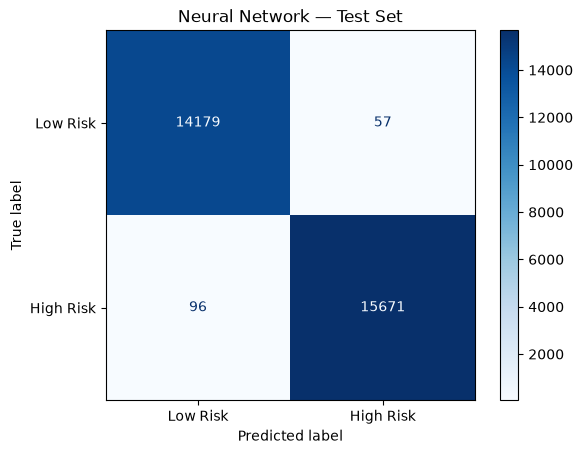

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot  as plt

y_test_prob=model.predict(
    X_test_processed,
    verbose=2
).ravel()

y_test_pred=(y_test_prob>=0.5).astype(int)

print("TEST SET RESULTS")
print('-'*40)
print(f"Accuracy: {accuracy_score(y_test,y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_test_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_test_prob):.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Low Risk", "High Risk"],
    digits=4
))

# Visualize correct and incorrect predictions
cm = confusion_matrix(y_test, y_test_pred)

display_labels = ["Low Risk", "High Risk"]
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
).plot(cmap="Blues", values_format="d")

plt.title("Neural Network — Test Set")
plt.show()

In [14]:
from pathlib import Path
import joblib

MODEL_DIR=Path(r"D:\patient_alert_system\models")
MODEL_DIR.mkdir(parents=True,exist_ok=True)

model_path=MODEL_DIR/"patient_risk_model.keras"
model.save(model_path)

preprocessor_path=MODEL_DIR/"patient_preprocessor.joblib"
joblib.dump(feature_columns,preprocessor_path)


feature_path = MODEL_DIR / "patient_feature_columns.joblib"
joblib.dump(feature_columns, feature_path)

print("Model saved to:", model_path)
print("Preprocessor saved to:", preprocessor_path)
print("Feature list saved to:", feature_path)

# Verify that the saved model can be loaded
loaded_model = keras.models.load_model(model_path)

print("\nModel loaded successfully!")
print("Model input shape:", loaded_model.input_shape)


Model saved to: D:\patient_alert_system\models\patient_risk_model.keras
Preprocessor saved to: D:\patient_alert_system\models\patient_preprocessor.joblib
Feature list saved to: D:\patient_alert_system\models\patient_feature_columns.joblib

Model loaded successfully!
Model input shape: (None, 11)
